# 6 - Métricas de fairness: modelos com e sem gênero

**Projeto final — SME0828 Introdução à Ciência de Dados**
Prof. Francisco A. Rodrigues — ICMC/USP

Grupo: _(nomes)_

<hr>

No notebook anterior treinamos dois modelos de crédito (Gradient Boosting): um **com** e outro **sem** a variável gênero. Vimos que o desempenho dos dois é praticamente igual, mas que ambos parecem negar mais pedidos de mulheres.

Neste notebook medimos isso formalmente, com **métricas de fairness** (justiça algorítmica). Elas respondem: *o modelo trata homens e mulheres de forma diferente?*

Vamos calcular, para cada modelo e também para as **decisões reais dos bancos** (como referência):
1. **paridade demográfica**: diferença na taxa de negação entre mulheres e homens;
2. **disparate impact**: razão entre as taxas de aprovação (regra dos 80%);
3. **diferença condicional ao risco**: a mesma diferença, mas comparando apenas pedidos com DTI e LTV parecidos.

Os intervalos de confiança de 95% são obtidos por **bootstrap**.

### 1. Bibliotecas

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

BLUE   = "#2a78d6"
ORANGE = "#eb6834"
GRAY   = "#898781"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

### 2. Leitura das previsões

O notebook `05_gradient_boosting` salvou as previsões dos dois modelos para os **459.866 pedidos do conjunto de teste**. Para cada pedido temos:
- `negado`: a decisão **real** do banco;
- `proba_com_genero` e `proba_sem_genero`: a **probabilidade** de negação estimada por cada modelo;
- `pred_com_genero` e `pred_sem_genero`: a **decisão** do modelo (0 ou 1), após aplicar o limiar.

In [2]:
data = pd.read_parquet("../resultados/h2_previsoes_teste.parquet")

print("Número de linhas e colunas:", data.shape)
print(f"Mulheres no teste: {data['mulher'].mean():.1%}")
data.head()

Número de linhas e colunas: (459866, 12)
Mulheres no teste: 38.9%


,negado,mulher,dti,ltv,log_renda,loan_type,state_code,applicant_age,proba_com_genero,proba_sem_genero,pred_com_genero,pred_sem_genero
0,0,1,36%-<50%,66.847,4.465908,1,AZ,35-44,0.029696,0.030865,0,0
1,0,0,36%-<50%,95.000,5.068904,1,CA,45-54,0.073745,0.074025,0,0
2,0,0,36%-<50%,97.000,4.418841,1,UT,25-34,0.028796,0.028624,0,0
3,0,1,36%-<50%,96.500,4.521789,2,MD,55-64,0.095660,0.094726,0,0
4,0,0,30%-<36%,80.000,5.176150,1,TN,25-34,0.027378,0.025507,0,0


Para facilitar, guardamos as três "decisões" que vamos comparar numa única tabela: a dos bancos e a dos dois modelos.

In [3]:
decisoes = {
    "Bancos (real)": data["negado"].values,
    "GB com gênero": data["pred_com_genero"].values,
    "GB sem gênero": data["pred_sem_genero"].values,
}
mulher = data["mulher"].values == 1

taxas = pd.DataFrame({
    nome: {"Homens": d[~mulher].mean(), "Mulheres": d[mulher].mean()}
    for nome, d in decisoes.items()
}).T
(100 * taxas).round(2)

,Homens,Mulheres
Bancos (real),9.93,11.34
GB com gênero,9.11,12.53
GB sem gênero,9.03,12.69


### 3. As métricas

Notação: $\hat{y} = 1$ é um pedido negado; F = mulheres; M = homens.

**Paridade demográfica (DP)**: diferença entre as taxas de negação.
$$DP = P(\hat{y}=1 \mid F) - P(\hat{y}=1 \mid M)$$
DP = 0 significa que os dois grupos são negados na mesma proporção. DP > 0 significa que mulheres são **mais** negadas.

**Disparate impact (DI)**: razão entre as taxas de **aprovação**.
$$DI = \frac{P(\hat{y}=0 \mid F)}{P(\hat{y}=0 \mid M)}$$
DI = 1 significa igualdade. Pela **regra dos 80%**, usada nos EUA em casos de discriminação, DI < 0,8 indica impacto adverso.

**Diferença condicional ao risco**: a DP calculada **dentro de grupos de pedidos com risco parecido** (mesma faixa de DTI e mesma faixa de LTV), depois combinada numa média ponderada pelo tamanho de cada grupo. Ela responde: *entre pedidos com o mesmo risco observável, o modelo ainda nega mais as mulheres?*

Para a métrica condicional, dividimos o LTV em 5 faixas (quintis) e cruzamos com as 6 faixas de DTI, formando 30 grupos (*estratos*).

In [4]:
data["faixa_ltv"] = pd.qcut(data["ltv"], q=5, duplicates="drop")
data["estrato"] = data["dti"].astype(str) + " | " + data["faixa_ltv"].astype(str)
estrato = data["estrato"].values

print("Número de estratos:", data["estrato"].nunique())
data["estrato"].value_counts().head()

Número de estratos: 30


estrato
36%-<50% | (89.5, 95.0]       59304
36%-<50% | (79.78, 89.5]      52038
36%-<50% | (95.0, 97.0]       50942
36%-<50% | (13.987, 79.78]    49337
36%-<50% | (97.0, 115.52]     49204
Name: count, dtype: int64

Calculamos as três métricas para cada decisão. A diferença condicional usa um `groupby` por estrato: em cada estrato, calculamos a taxa de negação de mulheres e de homens, e depois a média ponderada das diferenças.

In [5]:
resultados = []

for nome, d in decisoes.items():
    taxa_f = d[mulher].mean()
    taxa_m = d[~mulher].mean()

    por_estrato = pd.DataFrame({"estrato": estrato, "mulher": mulher, "d": d}).groupby(
        ["estrato", "mulher"])["d"].mean().unstack()
    tamanho = pd.Series(estrato).value_counts()
    dif_estrato = (por_estrato[True] - por_estrato[False]).dropna()
    condicional = np.average(dif_estrato, weights=tamanho[dif_estrato.index])

    resultados.append({
        "Decisão": nome,
        "Taxa homens (%)": 100 * taxa_m,
        "Taxa mulheres (%)": 100 * taxa_f,
        "DP (p.p.)": 100 * (taxa_f - taxa_m),
        "DI": (1 - taxa_f) / (1 - taxa_m),
        "DP condicional (p.p.)": 100 * condicional,
    })

metricas = pd.DataFrame(resultados).set_index("Decisão")
metricas.round(3)

,Taxa homens (%),Taxa mulheres (%),DP (p.p.),DI,DP condicional (p.p.)
Decisão,,,,,
Bancos (real),9.932,11.340,1.408,0.984,1.159
GB com gênero,9.108,12.533,3.425,0.962,3.475
GB sem gênero,9.031,12.687,3.656,0.960,3.717


### 4. Intervalos de confiança por bootstrap

Os valores acima são estimativas a partir de uma amostra (o conjunto de teste). Para saber se as diferenças são **estatisticamente** diferentes de zero, usamos o **bootstrap**:

1. sorteamos, **com reposição**, 459.866 pedidos do conjunto de teste (mesmo tamanho);
2. recalculamos as métricas nessa nova amostra;
3. repetimos 1.000 vezes;
4. o intervalo de 95% vai do percentil 2,5% ao 97,5% dos 1.000 valores obtidos.

Para não ficar lento, no bootstrap calculamos DP e DI (a métrica condicional usa o `groupby` e demoraria muito mais). Leva cerca de um minuto.

In [6]:
B = 1000
n = len(data)
boot = {nome: {"DP": [], "DI": []} for nome in decisoes}

for b in range(B):
    idx = np.random.randint(0, n, n)
    m = mulher[idx]
    for nome, d in decisoes.items():
        db = d[idx]
        taxa_f = db[m].mean()
        taxa_m = db[~m].mean()
        boot[nome]["DP"].append(100 * (taxa_f - taxa_m))
        boot[nome]["DI"].append((1 - taxa_f) / (1 - taxa_m))

for nome in decisoes:
    for metrica in ["DP", "DI"]:
        valores = np.array(boot[nome][metrica])
        metricas.loc[nome, f"{metrica} IC inf"] = np.percentile(valores, 2.5)
        metricas.loc[nome, f"{metrica} IC sup"] = np.percentile(valores, 97.5)

metricas[["DP (p.p.)", "DP IC inf", "DP IC sup", "DI", "DI IC inf", "DI IC sup", "DP condicional (p.p.)"]].round(3)

,DP (p.p.),DP IC inf,DP IC sup,DI,DI IC inf,DI IC sup,DP condicional (p.p.)
Decisão,,,,,,,
Bancos (real),1.408,1.223,1.586,0.984,0.982,0.986,1.159
GB com gênero,3.425,3.237,3.607,0.962,0.960,0.964,3.475
GB sem gênero,3.656,3.459,3.837,0.960,0.958,0.962,3.717


### 5. Visualização

O gráfico da esquerda mostra a **paridade demográfica** (em pontos percentuais) com o intervalo de 95%. O da direita mostra o **disparate impact**, com a linha da regra dos 80%.

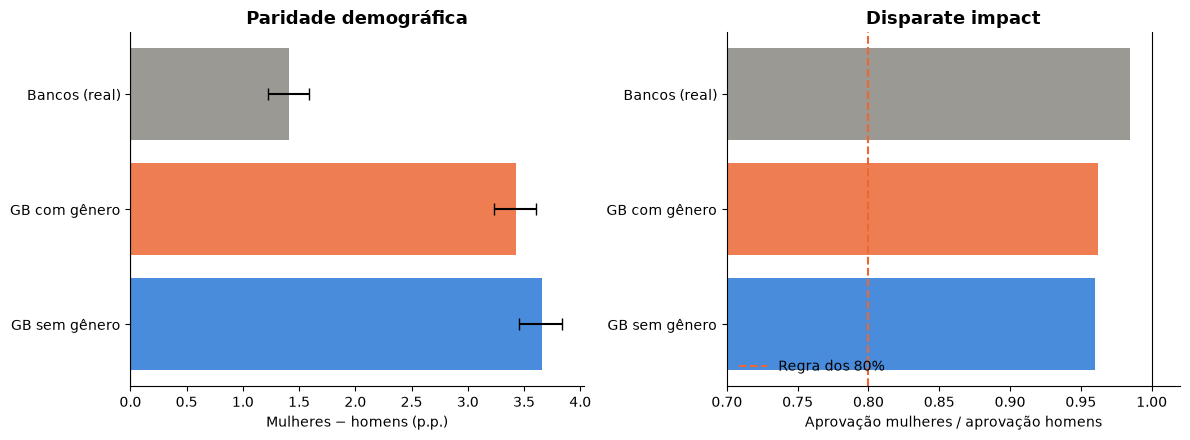

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
nomes = list(metricas.index)
y = np.arange(len(nomes))[::-1]
cores = [GRAY, ORANGE, BLUE]

axes[0].barh(y, metricas["DP (p.p.)"], color=cores, alpha=0.85)
axes[0].errorbar(metricas["DP (p.p.)"], y,
                 xerr=[metricas["DP (p.p.)"] - metricas["DP IC inf"], metricas["DP IC sup"] - metricas["DP (p.p.)"]],
                 fmt="none", ecolor="black", capsize=4)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Mulheres − homens (p.p.)")
axes[0].set_title("Paridade demográfica", fontsize=13, fontweight="bold")

axes[1].barh(y, metricas["DI"], color=cores, alpha=0.85)
axes[1].axvline(0.8, color=ORANGE, linestyle="--", linewidth=1.5, label="Regra dos 80%")
axes[1].axvline(1.0, color="black", linewidth=0.8)
axes[1].set_xlim(0.7, 1.02)
axes[1].set_xlabel("Aprovação mulheres / aprovação homens")
axes[1].set_title("Disparate impact", fontsize=13, fontweight="bold")
axes[1].legend(frameon=False, loc="lower left")

for ax in axes:
    ax.set_yticks(y)
    ax.set_yticklabels(nomes)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/fairness_dp_di.png", dpi=150)
plt.show()

### 6. De onde vem a diferença? Probabilidades vs. decisões

O modelo produz primeiro uma **probabilidade** de negação e só depois, aplicando um **limiar**, uma **decisão** (0 ou 1). Vamos comparar a diferença entre mulheres e homens nessas duas etapas.

Se a diferença for pequena nas probabilidades e grande nas decisões, então é o **limiar** que está amplificando a desigualdade.

In [8]:
etapas = pd.DataFrame({
    "Bancos (real)": [100 * (data["negado"][mulher].mean() - data["negado"][~mulher].mean()), np.nan],
    "GB com gênero": [100 * (data["proba_com_genero"][mulher].mean() - data["proba_com_genero"][~mulher].mean()),
                      metricas.loc["GB com gênero", "DP (p.p.)"]],
    "GB sem gênero": [100 * (data["proba_sem_genero"][mulher].mean() - data["proba_sem_genero"][~mulher].mean()),
                      metricas.loc["GB sem gênero", "DP (p.p.)"]],
}, index=["Diferença nas probabilidades (p.p.)", "Diferença nas decisões (p.p.)"]).T
etapas.round(2)

,Diferença nas probabilidades (p.p.),Diferença nas decisões (p.p.)
Bancos (real),1.41,NaN
GB com gênero,1.47,3.43
GB sem gênero,1.65,3.66


Para entender o efeito do limiar, olhamos a **distribuição das probabilidades** previstas pelo modelo sem gênero, separada por gênero. A linha tracejada é o limiar: tudo à direita dela vira "negado".

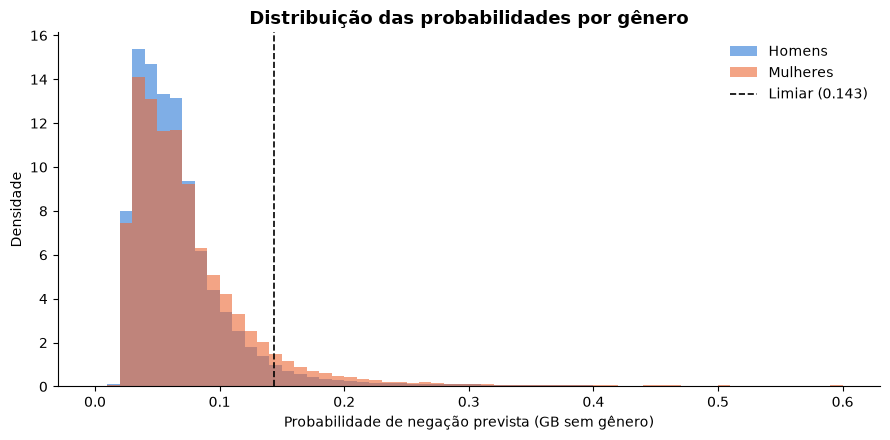

Probabilidade mediana - homens: 0.060
Probabilidade mediana - mulheres: 0.065


In [9]:
limiar = data.loc[data["pred_sem_genero"] == 1, "proba_sem_genero"].min()

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, 0.6, 61)
ax.hist(data.loc[~mulher, "proba_sem_genero"], bins=bins, density=True, alpha=0.6, color=BLUE, label="Homens")
ax.hist(data.loc[mulher, "proba_sem_genero"], bins=bins, density=True, alpha=0.6, color=ORANGE, label="Mulheres")
ax.axvline(limiar, color="black", linestyle="--", linewidth=1.2, label=f"Limiar ({limiar:.3f})")
ax.set_xlabel("Probabilidade de negação prevista (GB sem gênero)")
ax.set_ylabel("Densidade")
ax.set_title("Distribuição das probabilidades por gênero", fontsize=13, fontweight="bold")
ax.legend(frameon=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/fairness_distribuicao_probabilidades.png", dpi=150)
plt.show()

print(f"Probabilidade mediana - homens: {data.loc[~mulher, 'proba_sem_genero'].median():.3f}")
print(f"Probabilidade mediana - mulheres: {data.loc[mulher, 'proba_sem_genero'].median():.3f}")

### 7. Diferença condicional por estrato de risco

Por fim, olhamos a diferença (mulheres − homens) nas decisões do modelo **sem gênero** dentro de cada combinação de DTI e LTV. Cores laranja indicam que o modelo nega **mais** mulheres naquele estrato; azuis, que nega **menos**.

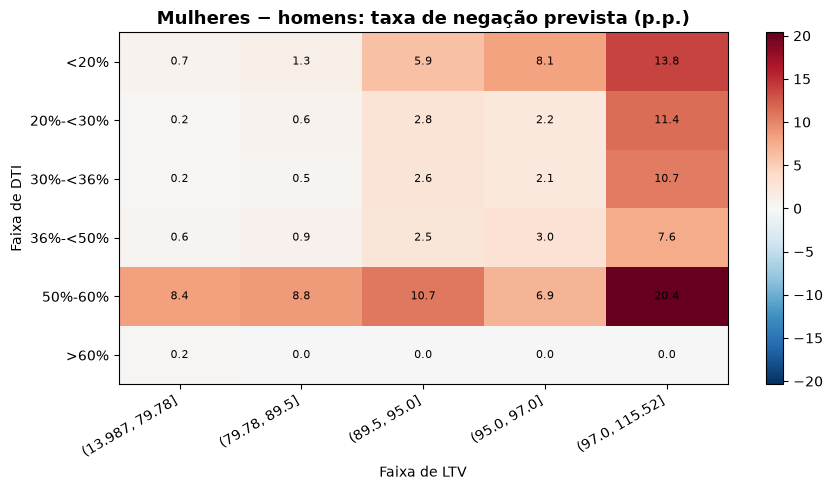

In [10]:
tabela_estratos = data.groupby(["dti", "faixa_ltv", "mulher"], observed=True)["pred_sem_genero"].mean().unstack()
mapa = (100 * (tabela_estratos[1] - tabela_estratos[0])).unstack()

# Coloca as faixas de DTI na ordem do menor para o maior risco
ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"]
mapa = mapa.reindex(ordem_dti)

fig, ax = plt.subplots(figsize=(9, 5))
limite = np.nanmax(np.abs(mapa.values))
im = ax.imshow(mapa.values, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
ax.set_xticks(range(mapa.shape[1]))
ax.set_xticklabels([str(c) for c in mapa.columns], rotation=30, ha="right")
ax.set_yticks(range(mapa.shape[0]))
ax.set_yticklabels(mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        if not np.isnan(mapa.values[i, j]):
            ax.text(j, i, f"{mapa.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("Faixa de LTV")
ax.set_ylabel("Faixa de DTI")
ax.set_title("Mulheres − homens: taxa de negação prevista (p.p.)", fontsize=13, fontweight="bold")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("../figuras/fairness_estratos.png", dpi=150)
plt.show()

### 8. Nota metodológica: métricas que não calculamos

Métricas como **equalized odds** (taxas de erro iguais entre grupos) e **calibração por grupo** exigem saber o **desfecho verdadeiro** de cada empréstimo, isto é, se a pessoa pagou ou não. O HMDA público **não contém informação de inadimplência**.

O único "rótulo" que temos é a **decisão do banco**, que pode ela mesma conter viés. Comparar os erros do modelo com essa decisão mediria apenas o quanto o modelo imita os bancos, e não o quanto ele é justo. Por isso, essas métricas **não são calculadas**.

### 9. Salvando os resultados

In [11]:
tabela_final = metricas.copy()
tabela_final["DP (IC 95%)"] = tabela_final.apply(lambda r: f"{r['DP (p.p.)']:.2f} ({r['DP IC inf']:.2f}; {r['DP IC sup']:.2f})", axis=1)
tabela_final["DI (IC 95%)"] = tabela_final.apply(lambda r: f"{r['DI']:.3f} ({r['DI IC inf']:.3f}; {r['DI IC sup']:.3f})", axis=1)
tabela_final["DP condicional"] = tabela_final["DP condicional (p.p.)"].map(lambda x: f"{x:.2f}")
tabela_final = tabela_final[["Taxa homens (%)", "Taxa mulheres (%)", "DP (IC 95%)", "DI (IC 95%)", "DP condicional"]].round(2)

with open("../resultados/fairness_metricas.md", "w", encoding="utf-8") as f:
    f.write(tabela_final.to_markdown())
    f.write("\n\nDP em pontos percentuais (mulheres − homens) na taxa de negação. DI = aprovação mulheres / aprovação homens "
            "(regra dos 80%: DI < 0,8). DP condicional: média ponderada da DP em 30 estratos de DTI × quintil de LTV. "
            "IC 95% por bootstrap (1.000 reamostragens do conjunto de teste, n = 459.866).\n")
tabela_final

,Taxa homens (%),Taxa mulheres (%),DP (IC 95%),DI (IC 95%),DP condicional
Decisão,,,,,
Bancos (real),9.93,11.34,1.41 (1.22; 1.59),0.984 (0.982; 0.986),1.16
GB com gênero,9.11,12.53,3.43 (3.24; 3.61),0.962 (0.960; 0.964),3.48
GB sem gênero,9.03,12.69,3.66 (3.46; 3.84),0.960 (0.958; 0.962),3.72


### Conclusão

- **Decisões reais dos bancos:** mulheres são negadas **1,41 p.p.** a mais que homens (IC 95%: 1,22 a 1,59). Comparando apenas pedidos com DTI e LTV parecidos, a diferença cai para **1,16 p.p.**
- **Modelos de crédito:** os dois Gradient Boosting **mais que dobram** essa diferença. O modelo **com** gênero nega 3,43 p.p. a mais as mulheres, e o modelo **sem** gênero nega **3,66 p.p.** a mais (IC 95%: 3,46 a 3,84). Os intervalos dos modelos não se sobrepõem ao dos bancos.
- **Retirar o gênero não resolve:** o modelo sem a variável `mulher` é, na verdade, ligeiramente **mais** desigual que o modelo com ela. Isso confirma a **H2**: outras variáveis carregam a informação de gênero, e a disparidade persiste.
- **A diferença continua entre perfis de risco parecidos:** a DP condicional do modelo sem gênero é de 3,72 p.p., e o mapa de calor mostra mulheres mais negadas em **praticamente todos** os estratos de DTI e LTV. A diferença é maior nos pedidos com **LTV alto** (acima de 97%) e com DTI entre 50% e 60%, chegando a 20 p.p.
- **O limiar amplifica a desigualdade:** nas **probabilidades**, a diferença entre mulheres e homens é de apenas 1,65 p.p., próxima à dos bancos. Nas **decisões**, ela sobe para 3,66 p.p. A distribuição de probabilidades das mulheres tem a cauda direita um pouco mais pesada; como o limiar (0,143) fica justamente nessa região, uma diferença pequena nas probabilidades vira uma diferença grande nas decisões.
- **Regra dos 80%:** todos os *disparate impacts* ficam acima de 0,95, bem longe do limite de 0,8. Pelo critério legal americano, **não** haveria impacto adverso. Isso mostra que as métricas contam histórias diferentes: a DP é estatisticamente significativa, mas pequena em termos relativos, porque a taxa de aprovação é alta para os dois grupos (cerca de 90%).
- Na faixa de DTI acima de 60%, o modelo nega **todos** os pedidos dos dois gêneros (por isso a diferença é zero nessa linha do mapa).

**Próximo passo (Etapa F):** identificar **quais variáveis** funcionam como proxy do gênero, treinando um classificador que tenta adivinhar o gênero a partir delas e analisando a importância de cada uma com SHAP.